<a href="https://colab.research.google.com/github/likhithlikhi192005-bot/Brain-Tumor-Detection-Using-CNN/blob/main/Likhith_H_S_(20241CSE0596).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==========================================
# CELL 1: IMPORT LIBRARIES
# ==========================================

import os
import zipfile
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from google.colab import files

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("All libraries imported successfully!")

# Upload ZIP dataset
uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))

print("\nUploaded file:", zip_name)

All libraries imported successfully!


Saving archive.zip to archive.zip

Uploaded file: archive.zip


In [2]:
# ==========================================
# CELL 2: EXTRACT AND ORGANIZE DATASET
# ==========================================

extract_path = "/content/brain_tumor_raw"
organized_path = "/content/brain_tumor_dataset"

os.makedirs(extract_path, exist_ok=True)

# Extract ZIP
with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP file extracted successfully!")

# Create organized folders
for split in ['train', 'test']:
    for category in ['no_tumor', 'tumor']:
        os.makedirs(
            os.path.join(organized_path, split, category),
            exist_ok=True
        )

# Find and organize images
image_extensions = {'.jpg', '.jpeg'}

image_paths = list(Path(extract_path).rglob('*'))

counts = {
    'train': {'no_tumor': 0, 'tumor': 0},
    'test': {'no_tumor': 0, 'tumor': 0}
}

for image_path in image_paths:

    if not image_path.is_file():
        continue

    if image_path.suffix.lower() not in image_extensions:
        continue

    parts = [part.lower() for part in image_path.parts]

    # Ignore mask folders
    if any('mask' in part for part in parts):
        continue

    # Identify category
    if 'no tumor' in parts:
        category = 'no_tumor'
    elif 'tumor' in parts:
        category = 'tumor'
    else:
        continue

    # Identify training or testing folder
    if 'train' in parts:
        split = 'train'
    elif 'test' in parts:
        split = 'test'
    else:
        continue

    destination = os.path.join(
        organized_path,
        split,
        category,
        image_path.name
    )

    # Avoid overwriting files with duplicate names
    if os.path.exists(destination):
        base = image_path.parent.name + "_" + image_path.name
        destination = os.path.join(
            organized_path, split, category, base
        )

    shutil.copy2(image_path, destination)
    counts[split][category] += 1

print("\nDataset organized successfully!")

print("\nTraining Images:")
print(counts['train'])

print("\nTesting Images:")
print(counts['test'])

print("\nTotal Images:", sum(sum(v.values()) for v in counts.values()))

ZIP file extracted successfully!

Dataset organized successfully!

Training Images:
{'no_tumor': 501, 'tumor': 500}

Testing Images:
{'no_tumor': 100, 'tumor': 100}

Total Images: 1201


In [3]:
# ==========================================
# CELL 3: DATASET INFORMATION
# ==========================================

categories = ['no_tumor', 'tumor']

for split in ['train', 'test']:

    print(f"\n{split.upper()} DATASET")

    for category in categories:

        folder = os.path.join(
            organized_path, split, category
        )

        total = len([
            f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg'))
        ])

        print(category, ":", total, "images")

print("\nClass Labels:")
print("0 = No Tumor")
print("1 = Tumor")


TRAIN DATASET
no_tumor : 501 images
tumor : 500 images

TEST DATASET
no_tumor : 100 images
tumor : 100 images

Class Labels:
0 = No Tumor
1 = Tumor


In [4]:
# ==========================================
# CELL 4: LOAD IMAGE DATASET
# ==========================================

IMG_SIZE = (180, 180)
BATCH_SIZE = 32

train_directory = os.path.join(organized_path, 'train')
test_directory = os.path.join(organized_path, 'test')

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_directory,
    validation_split=0.2,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=['no_tumor', 'tumor']
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    train_directory,
    validation_split=0.2,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=['no_tumor', 'tumor']
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_directory,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    class_names=['no_tumor', 'tumor']
)

class_names = train_ds.class_names

print("\nClass Names:", class_names)
print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)

# Improve input pipeline performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
validation_ds = validation_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 1001 files belonging to 2 classes.
Using 801 files for training.
Found 1001 files belonging to 2 classes.
Using 200 files for validation.
Found 200 files belonging to 2 classes.

Class Names: ['no_tumor', 'tumor']
Image Size: (180, 180)
Batch Size: 32


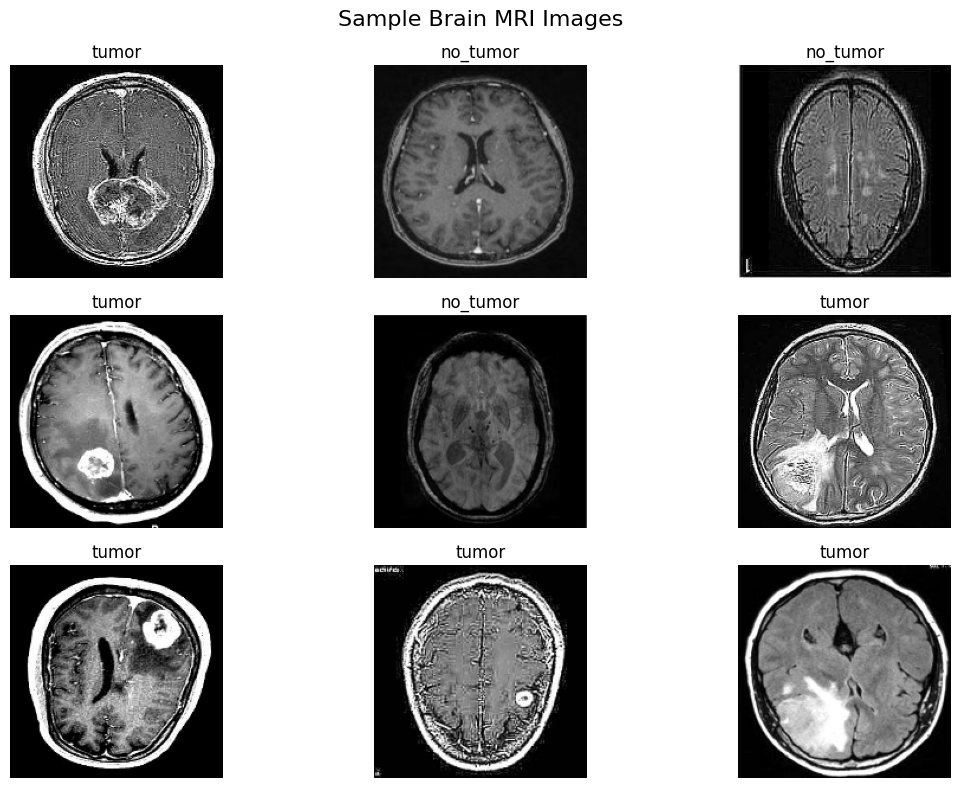

In [5]:
# ==========================================
# CELL 5: DISPLAY SAMPLE MRI IMAGES
# ==========================================

plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):

    for i in range(min(9, len(images))):

        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy())

        plt.title(class_names[label])
        plt.axis('off')

plt.suptitle("Sample Brain MRI Images", fontsize=16)
plt.tight_layout()
plt.show()

In [6]:
# ==========================================
# CELL 6: BUILD CNN MODEL
# ==========================================

model = keras.Sequential([

    layers.Input(shape=(180, 180, 3)),

    # Normalize image pixels
    layers.Rescaling(1./255),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 180, 180, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# ==========================================
# CELL 7: TRAIN CNN MODEL
# ==========================================

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=20,
    callbacks=[early_stopping]
)

print("\nCNN Model Training Completed!")

Epoch 1/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 72s 3s/step - accuracy: 0.7179 - loss: 0.6480 - val_accuracy: 0.6850 - val_loss: 0.7297
Epoch 2/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 80s 3s/step - accuracy: 0.8040 - loss: 0.4196 - val_accuracy: 0.8400 - val_loss: 0.3024
Epoch 3/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 66s 3s/step - accuracy: 0.8340 - loss: 0.4295 - val_accuracy: 0.8450 - val_loss: 0.3106
Epoch 4/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 66s 3s/step - accuracy: 0.8489 - loss: 0.3528 - val_accuracy: 0.8950 - val_loss: 0.2815
Epoch 5/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 69s 3s/step - accuracy: 0.8589 - loss: 0.3206 - val_accuracy: 0.8800 - val_loss: 0.3139
Epoch 6/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.8939 - loss: 0.2775 - val_accuracy: 0.9250 - val_loss: 0.2117
Epoch 7/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.9039 - loss: 0.2372 - val_accuracy: 0.9400 - val_loss: 0.1810
Epoch 8/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.9276 - loss: 0.1827 - val_accuracy: 0.9150 - val_loss:

In [8]:
# ==========================================
# CELL 8: MODEL EVALUATION
# ==========================================

test_loss, test_accuracy = model.evaluate(test_ds)

print("\n========== MODEL PERFORMANCE ==========")

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))

7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 486ms/step - accuracy: 0.8650 - loss: 0.3168

========== MODEL PERFORMANCE ==========
Test Loss: 0.3168
Test Accuracy: 0.865


In [9]:
# ==========================================
# CELL 9: GENERATE PREDICTIONS
# ==========================================

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = model.predict(test_ds).ravel()

y_pred = (y_prob >= 0.5).astype(int)

print("Predictions generated successfully!")

print("\nActual Values (First 10):")
print(y_true[:10])

print("\nPredicted Values (First 10):")
print(y_pred[:10])

7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 668ms/step
Predictions generated successfully!

Actual Values (First 10):
[0 0 0 0 0 0 0 0 0 0]

Predicted Values (First 10):
[0 0 0 0 0 0 0 0 0 0]


In [10]:
# ==========================================
# CELL 10: MODEL PERFORMANCE METRICS
# ==========================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_true, y_prob)

print("========== CNN MODEL PERFORMANCE ==========")

print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))
print("ROC AUC   :", round(roc_auc, 4))

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_true,
    y_pred,
    target_names=['No Tumor', 'Tumor'],
    zero_division=0
))

========== CNN MODEL PERFORMANCE ==========
Accuracy  : 0.865
Precision : 0.8614
Recall    : 0.87
F1 Score  : 0.8657
ROC AUC   : 0.9366

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

    No Tumor       0.87      0.86      0.86       100
       Tumor       0.86      0.87      0.87       100

    accuracy                           0.86       200
   macro avg       0.87      0.86      0.86       200
weighted avg       0.87      0.86      0.86       200



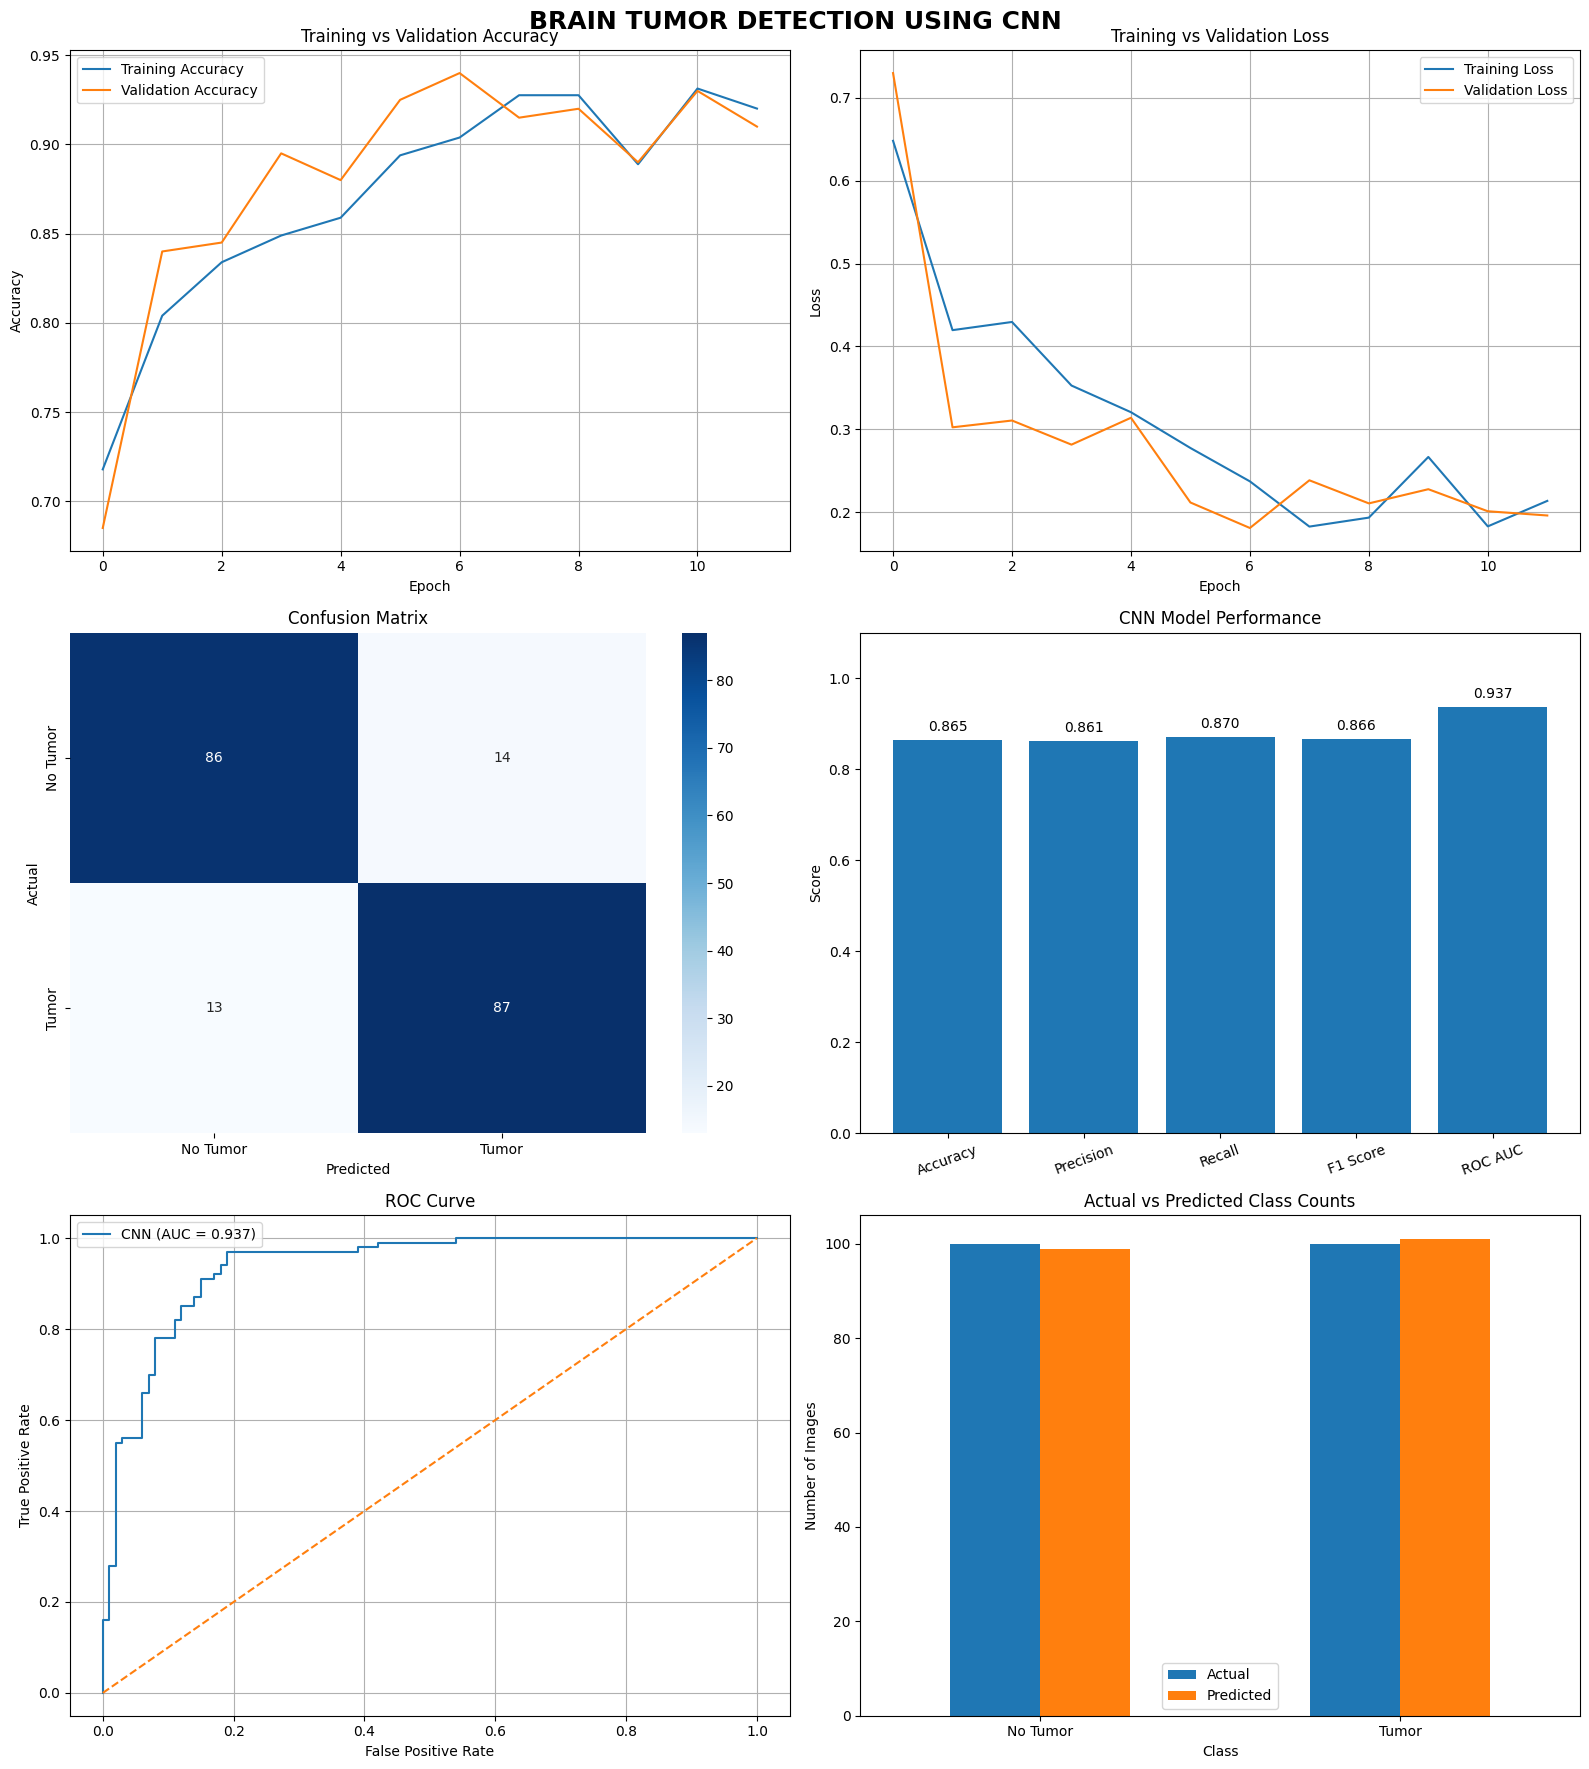


========== FINAL MODEL RESULTS ==========
Accuracy  : 0.8650
Precision : 0.8614
Recall    : 0.8700
F1 Score  : 0.8657
ROC AUC   : 0.9366


In [11]:
# ==========================================
# CELL 11: COMPLETE PROJECT VISUALIZATION
# ==========================================

fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Training and Validation Accuracy
axes[0, 0].plot(history.history['accuracy'], label='Training Accuracy')
axes[0, 0].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[0, 0].set_title("Training vs Validation Accuracy")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].legend()
axes[0, 0].grid()

# 2. Training and Validation Loss
axes[0, 1].plot(history.history['loss'], label='Training Loss')
axes[0, 1].plot(history.history['val_loss'], label='Validation Loss')
axes[0, 1].set_title("Training vs Validation Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid()

# 3. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Tumor', 'Tumor'],
    yticklabels=['No Tumor', 'Tumor'],
    ax=axes[1, 0]
)

axes[1, 0].set_title("Confusion Matrix")
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("Actual")

# 4. Model Performance
metrics = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1,
    'ROC AUC': roc_auc
}

axes[1, 1].bar(metrics.keys(), metrics.values())
axes[1, 1].set_title("CNN Model Performance")
axes[1, 1].set_ylabel("Score")
axes[1, 1].set_ylim(0, 1.1)
axes[1, 1].tick_params(axis='x', rotation=20)

for i, value in enumerate(metrics.values()):
    axes[1, 1].text(
        i, value + 0.02,
        f'{value:.3f}',
        ha='center'
    )

# 5. ROC Curve
fpr, tpr, thresholds = roc_curve(y_true, y_prob)

axes[2, 0].plot(
    fpr, tpr,
    label=f'CNN (AUC = {roc_auc:.3f})'
)

axes[2, 0].plot([0, 1], [0, 1], linestyle='--')
axes[2, 0].set_title("ROC Curve")
axes[2, 0].set_xlabel("False Positive Rate")
axes[2, 0].set_ylabel("True Positive Rate")
axes[2, 0].legend()
axes[2, 0].grid()

# 6. Actual vs Predicted Distribution
comparison = pd.DataFrame({
    'Actual': y_true,
    'Predicted': y_pred
})

comparison_counts = pd.DataFrame({
    'Actual': comparison['Actual'].value_counts().reindex([0, 1], fill_value=0),
    'Predicted': comparison['Predicted'].value_counts().reindex([0, 1], fill_value=0)
})

comparison_counts.index = ['No Tumor', 'Tumor']
comparison_counts.plot(
    kind='bar',
    ax=axes[2, 1]
)

axes[2, 1].set_title("Actual vs Predicted Class Counts")
axes[2, 1].set_xlabel("Class")
axes[2, 1].set_ylabel("Number of Images")
axes[2, 1].tick_params(axis='x', rotation=0)
axes[2, 1].legend()

plt.suptitle(
    "BRAIN TUMOR DETECTION USING CNN",
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

print("\n========== FINAL MODEL RESULTS ==========")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC AUC   : {roc_auc:.4f}")

In [13]:

# ==========================================
# CELL 12: PREDICT NEW MRI IMAGE
# ==========================================

import os
import zipfile
from PIL import Image, UnidentifiedImageError

print("Upload ONE brain MRI image (JPG, JPEG or PNG)")
uploaded_image = files.upload()

image_name = next(iter(uploaded_image.keys()))

# Check whether the uploaded file is a ZIP
if zipfile.is_zipfile(image_name):
    print("\nERROR: You uploaded a ZIP file.")
    print("Please extract archive.zip and upload one MRI image.")

else:
    try:
        # Load and resize MRI image
        img = keras.utils.load_img(
            image_name,
            target_size=(180, 180)
        )

        img_array = keras.utils.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)

        # Predict
        prediction_probability = model.predict(img_array, verbose=0)[0][0]

        print("\n========== BRAIN MRI PREDICTION ==========")

        if prediction_probability >= 0.5:
            print("Model Prediction: TUMOR")
        else:
            print("Model Prediction: NO TUMOR")

        print(f"Tumor Probability: {prediction_probability * 100:.2f}%")
        print(f"No Tumor Probability: {(1-prediction_probability) * 100:.2f}%")

        # Display image
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.title("Uploaded Brain MRI Image")
        plt.axis("off")
        plt.show()

    except (UnidentifiedImageError, OSError):
        print("Invalid image. Please upload a valid JPG, JPEG or PNG file.")


Upload ONE brain MRI image (JPG, JPEG or PNG)


Saving archive.zip to archive (2).zip

ERROR: You uploaded a ZIP file.
Please extract archive.zip and upload one MRI image.


In [14]:
# ==========================================
# CELL 13: SAVE TRAINED MODEL
# ==========================================

model.save("Brain_Tumor_Detection_CNN.keras")

print("Model saved successfully!")

files.download("Brain_Tumor_Detection_CNN.keras")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>